In [1]:
from osgeo import gdal
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [2]:
dataset = gdal.Open('./out2019.tif')

In [3]:
out = gdal.Warp('', dataset, width=256, height=256, outputBounds=[94.017,28.015,95.127,27.029], format='MEM')
print(out.GetRasterBand(4).ReadAsArray())

[[421 442 466 ...   0   0   0]
 [667 703 671 ...   0   0   0]
 [755 948 831 ...   0   0   0]
 ...
 [103 125 144 ... 118 113 126]
 [123 156 106 ...  72  66  65]
 [ 94 185 148 ...   0   0   0]]


In [9]:
def get_dataset(layer='http://mobileapp.nesdr.gov.in/out2019.tif', projWin=[10566654.790142765,3169996.4370428305,10605790.548624776,3209132.19552484], coord_sys="EPSG:4326"):
    projWin = coord(projWin, coord_sys)
    dataset = gdal.Open(
        #'/vsicurl/'+layer,
        './main/out2019.tif',
        gdal.GA_ReadOnly
        )
    out = gdal.Warp('', dataset, width=256, height=256, outputBounds=projWin, format='MEM')
    return out

In [4]:
class B():
    def __init__(self,dataset=None, band_no=0, band=None):
        #print(band_no, dataset)
        if dataset is None:
            self._band = band
        else:
            self._band = norm(np.array(dataset.GetRasterBand(band_no).ReadAsArray()))
    
    @property
    def band(self):
        return self._band
    
    def __add__(self,y):
        return B(band=self._band+y.band)
    
    def __sub__(self, y):
        return B(band=self._band-y.band)
    
    def __mul__(self, y):
        return B(band=np.multiply(self._band,y.band))
    
    def __truediv__(self, y):
        return B(band=np.divide(self._band, y.band, out=np.zeros_like(self._band), where=y.band!=0))

In [5]:
def apply_cmap(im, cmap):
    if cmap=='red':
        return np.dstack((np.zeros(im.shape),np.zeros(im.shape),im))
    elif cmap=='green':
        return np.dstack((np.zeros(im.shape),im,np.zeros(im.shape)))
    elif cmap=='blue':
        return np.dstack((im,np.zeros(im.shape),np.zeros(im.shape)))
    else:
        return im

In [23]:
def norm(x, y=None, z=None, minR=0, maxR=1, minG=0, maxG=1, minB=0, maxB=1):
    if y is None and z is None:
        x = x/2500
        x = ((maxR-minR)*x)+minR
        return x
    x = x/2500
    y = y/2500
    z = z/4000
    x = ((maxB-minB)*x)+minB
    y = ((maxG-minG)*y)+minG
    z = ((maxR-minR)*z)+minR
    return x, y, z

In [18]:
def norm(
    x, y=None, z=None,
    op_minR=0, op_maxR=1,
    op_minG=0, op_maxG=1,
    op_minB=0, op_maxB=1,
    ip_minR=0, ip_maxR=2500,
    ip_minG=0, ip_maxG=2500,
    ip_minB=0, ip_maxB=4000):
    if y is None and z is None:
        indices = np.where(x==0)
        x = (x-ip_minR)/(ip_maxR-ip_minR)
        x = ((op_maxR-op_minR)*x)+op_minR
        x[indices] = 0
        return x * 255.0
    indices1 = np.where(x==0)
    indices2 = np.where(y==0)
    indices3 = np.where(z==0)
    x = (x-ip_minB)/(ip_maxB-ip_minB)
    y = (x-ip_minG)/(ip_maxG-ip_minG)
    z = (x-ip_minR)/(ip_maxB-ip_minR)
    x = ((op_maxB-op_minB)*x)+op_minB
    y = ((op_maxG-op_minG)*y)+op_minG
    z = ((op_maxR-op_minR)*z)+op_minR
    x[indices1] = 0
    y[indices2] = 0
    z[indices3] = 0
    return x * 255.0, y * 255.0, z * 255.0

In [24]:
def setup(R, G=None, B=None, weight=None, minR=0, maxR=1, minG=0, maxG=1, minB=0, maxB=1, cmap='std'):
    if (np.max(R.band)==0 and G is None and B is None) or (np.max(R.band)==0 and np.max(G.band)==0 and np.max(B.band)==0):
        im = np.zeros((256,256,4))
        img = Image.fromarray(im, mode='RGBA')
        response = HttpResponse(content_type="image/png")
        img.save(response, "PNG")
        return response
    if weight is None:
        weight = [1,1,1]
    if G is None and B is None:
        im = np.array(norm(weight[0]*R.band, minR, maxR, minG, maxG, minB, maxB)[0])
        im = apply_cmap(im, cmap)
    else:
        im = np.dstack(norm(weight[0]*R.band, weight[1]*G.band, weight[2]*B.band, minR, maxR, minG, maxG, minB, maxB))
    _, ar = cv2.imencode('.png',im * 255)
    return im

In [20]:
def setup(
    R, G=None, B=None,
    weight=None, 
    op_minR=0, op_maxR=1, 
    op_minG=0, op_maxG=1, 
    op_minB=0, op_maxB=1,  
    ip_minR=-0.5, ip_maxR=0.8, 
    ip_minG=-0.5, ip_maxG=0.8, 
    ip_minB=-0.5, ip_maxB=0.8,
    cmap=None,
    cmap_order=1
    ):
    print('--------',R.band.min(),R.band.max())
    print('--------',G.band.min(),G.band.max())
    print('--------',B.band.min(),B.band.max())
    if (np.max(R.band)==0 and G is None and B is None) or (np.max(R.band)==0 and np.max(G.band)==0 and np.max(B.band)==0):
        im = np.zeros((256,256,4))
        img = Image.fromarray(im, mode='RGBA')
        response = HttpResponse(content_type="image/png")
        img.save(response, "PNG")
        return response
    if weight is None:
        weight = [1,1,1]
    if G is None and B is None:
        print('////////////=========++++++++++++++')
        im  = weight[0] * R.band
        if cmap is not None and cmap_order==1:
            im = apply_cmap(im, cmap)
        im = np.array(norm(
            x = im,
            op_minR=op_minR, op_maxR=op_maxR,
            ip_minR=ip_minR, ip_maxR=ip_maxR))
        if cmap is not None and cmap_order==0:
            im = apply_cmap(im, cmap)
    else:
        im = np.dstack(norm(
            x=weight[0]*R.band, 
            y=weight[1]*G.band, 
            z=weight[2]*B.band,
            op_minR=op_minR, op_maxR=op_maxR,
            op_minG=op_minG, op_maxG=op_maxG,
            op_minB=op_minB, op_maxB=op_maxB,
            ip_minR=ip_minR, ip_maxR=ip_maxR,
            ip_minG=ip_minG, ip_maxG=ip_maxG,
            ip_minB=ip_minB, ip_maxB=ip_maxB))
        print('=========',im.max(),im.min())
    return im

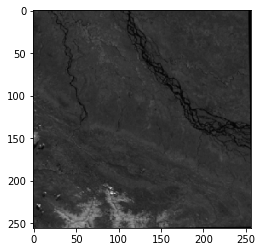

In [33]:
r = B(dataset=out,band_no=8)
g = B(dataset=out,band_no=4)

plt.imshow(setup(R=r),cmap='gray')

In [21]:
r = B(dataset=out, band_no=8)
g = B(dataset=out, band_no=4)
b = B(dataset=out, band_no=3)
response = setup(
  R=r,G=g,B=b,
  ip_minR=0,ip_maxR=2500,
  ip_minB=0,ip_maxB=2500,
  ip_minG=0,ip_maxG=4000,
)

-------- 0.0 1278.672
-------- 0.0 1245.5220000000002
-------- 0.0 1249.7040000000002
========= 130.42454400000003 0.0


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


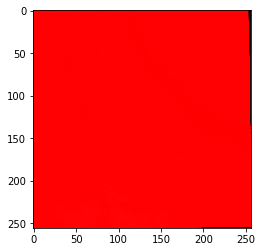

In [22]:
plt.imshow(response)

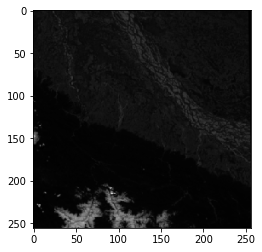

In [34]:
plt.imshow(setup(R=g),cmap='gray')

In [39]:
print(r.band)
print('=================')
print(g.band)

[[0.7296 0.7544 0.802  ... 0.     0.     0.    ]
 [1.0624 1.0956 1.188  ... 0.     0.     0.    ]
 [1.0448 0.8376 1.0596 ... 0.     0.     0.    ]
 ...
 [0.5184 0.5696 0.6796 ... 0.8808 0.8428 0.8608]
 [0.6696 0.7568 0.5128 ... 0.4604 0.4424 0.4208]
 [0.5504 1.128  0.9108 ... 0.     0.     0.    ]]
[[0.1684 0.1768 0.1864 ... 0.     0.     0.    ]
 [0.2668 0.2812 0.2684 ... 0.     0.     0.    ]
 [0.302  0.3792 0.3324 ... 0.     0.     0.    ]
 ...
 [0.0412 0.05   0.0576 ... 0.0472 0.0452 0.0504]
 [0.0492 0.0624 0.0424 ... 0.0288 0.0264 0.026 ]
 [0.0376 0.074  0.0592 ... 0.     0.     0.    ]]


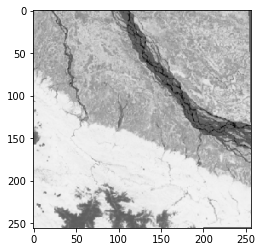

In [25]:
ndvi = (r-g)/(r+g)
plt.imshow(setup(R=ndvi),cmap='gray')

In [44]:
ndvi.band

array([[0.62494432, 0.62027491, 0.62282477, ..., 0.        , 0.        ,
        0.        ],
       [0.59855552, 0.59151656, 0.63141994, ..., 0.        , 0.        ,
        0.        ],
       [0.55152955, 0.37672584, 0.52241379, ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.85275197, 0.83860555, 0.84373304, ..., 0.89827586, 0.8981982 ,
        0.88937665],
       [0.86310518, 0.84765625, 0.84726225, ..., 0.88225675, 0.88737201,
        0.88361683],
       [0.87210884, 0.87687188, 0.87793814, ..., 0.        , 0.        ,
        0.        ]])

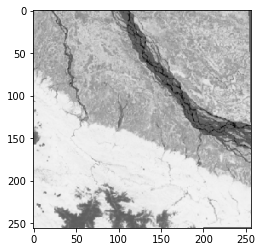

In [27]:
ndvi = (r-g)/(r+g)
plt.imshow(setup(R=ndvi,maxR=0.5),cmap='gray')